<a href="https://colab.research.google.com/github/IvonneRomero1008/IA-Trabajos-escolares/blob/main/Calculadora_EcoPrompt_MX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

excel_path = "Formulario sin título (Respuestas).xlsx"

df = pd.read_excel(
    excel_path,
    sheet_name="Respuestas de formulario 1"
)

print(f"Dimensiones de la base de datos: {df.shape}")

Dimensiones de la base de datos: (31, 27)


In [2]:
# Diccionarios de mapeo
freq_uso_map = {
    '1 a 2 días': 1,
    '3 a 4 días': 2,
    'Todos los días': 3
}

prompts_map = {
    'Menos de 5': 1,
    'De 5 a 15': 2,
    'De 16 a 30': 3,
    'Más de 30': 4
}

reintentos_map = {
    'Rara vez reintento (1 sola vez y cambio de tema o lo busco en Google)': 1,
    '2 a 3 veces refino la pregunta': 2,
    '4 a 6 veces sigo ajustando el prompt hasta obtener lo que quiero': 3,
    'Más de 6 reintentos continuos en la misma consulta': 4
}

sin_cambio_map = {
    'Nunca': 1,
    'A veces': 2,
    'Frecuentemente': 3,
    'Siempre': 4
}

capacitacion_map = {
    'No': 0,
    'Si, por cuenta propia': 1,
    'Si, impartido por la universidad': 2
}

clean_df = pd.DataFrame()

clean_df['Frecuencia_Uso'] = df[
    '¿Cuantos días a la semana ocupas herramientas de IA?'
].map(freq_uso_map)

clean_df['Cantidad_Prompts'] = df[
    'En los días que utilizas IA, ¿cuántos mensajes o instrucciones (prompts) en total envías al día? (Recuerda que un chat puede tener varios prompts o reintentos)'
].map(prompts_map)

clean_df['Reintentos'] = df[
    'Cuando la IA te da una respuesta incompleta o incorrecta, ¿cuántas veces sueles reintentar/reformular el mismo prompt en esa misma sesión?'
].map(reintentos_map)

clean_df['Trabajo_Sin_Cambio'] = df[
    '¿Con qué frecuencia entregas un trabajo o tarea académica con la respuesta de la IA sin realizar cambios significativos?'
].map(sin_cambio_map)

clean_df['Capacitacion_Previa'] = df[
    '¿Has recibido previamente algún curso, taller o capacitación sobre el uso correcto de la IA?'
].map(capacitacion_map)

def score_necesidad(text):
    if pd.isna(text):
        return 1
    return text.count(',') + 1

clean_df['Necesidad_Complejidad'] = df[
    '¿Para qué necesidades específicas utilizas la IA principalmente?'
].apply(score_necesidad)

clean_df = clean_df.fillna(1)

def asignar_perfil(row):
    score = (
        row['Frecuencia_Uso'] * 1.5 +
        row['Cantidad_Prompts'] * 2.0 +
        row['Reintentos'] * 1.5 +
        row['Capacitacion_Previa'] * 2.0 +
        row['Necesidad_Complejidad'] * 1.0 -
        row['Trabajo_Sin_Cambio'] * 1.0
    )

    if score <= 7:
        return 0
    elif score <= 12:
        return 1
    else:
        return 2

clean_df['Perfil_Observado'] = clean_df.apply(asignar_perfil, axis=1)

clean_df.head()

,Frecuencia_Uso,Cantidad_Prompts,Reintentos,Trabajo_Sin_Cambio,Capacitacion_Previa,Necesidad_Complejidad,Perfil_Observado
0,2,4,4,2,0,1,2
1,3,3,2,2,0,5,2
2,1,2,3,2,1,3,2
3,1,1,2,1,1,4,1
4,2,2,1,1,0,1,1


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models

X = clean_df[
    [
        'Frecuencia_Uso',
        'Cantidad_Prompts',
        'Reintentos',
        'Trabajo_Sin_Cambio',
        'Capacitacion_Previa',
        'Necesidad_Complejidad'
    ]
].values

y = clean_df['Perfil_Observado'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=60,
    batch_size=4,
    validation_data=(X_test_scaled, y_test),
    verbose=1
)

Epoch 1/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - accuracy: 0.3750 - loss: 1.0962 - val_accuracy: 0.4286 - val_loss: 1.0735
Epoch 2/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.4583 - loss: 1.0809 - val_accuracy: 0.5714 - val_loss: 1.0685
Epoch 3/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5000 - loss: 1.0681 - val_accuracy: 0.5714 - val_loss: 1.0642
Epoch 4/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5000 - loss: 1.0562 - val_accuracy: 0.5714 - val_loss: 1.0614
Epoch 5/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5417 - loss: 1.0441 - val_accuracy: 0.5714 - val_loss: 1.0589
Epoch 6/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5417 - loss: 1.0338 - val_accuracy: 0.5714 - val_loss: 1.0565
Epoch 7/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5417 - loss: 1.0219 - val_accuracy: 0.5714 - val_loss: 1.0525
Epoch 8/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5417 - loss: 1.0103 - val_accuracy: 0.5714 - val_loss: 1.0487

In [4]:
# Librerías necesarias para EcoPrompt MX
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Librerías de EcoPrompt MX cargadas correctamente.")

Librerías de EcoPrompt MX cargadas correctamente.


In [6]:
# FACTORES DE CONSUMO POR CONSULTA
# Los valores representan una consulta de texto estándar.
# No son valores universales: cambian según el modelo, la longitud
# del prompt, la región y la infraestructura del proveedor.

escenarios = {
    "Bajo": {
        "electricidad_wh": 0.24,
        "agua_ml": 0.26
    },
    "Promedio": {
        "electricidad_wh": 0.34,
        "agua_ml": 0.32
    },
    "Alto": {
        "electricidad_wh": 0.5,
        "agua_ml": 0.90
    }
}

# Tarifa eléctrica comercial utilizada en el problema prototípico
tarifa_electrica = 3.80       # MXN por kWh

# Factor de emisión del Sistema Eléctrico Nacional
factor_emision = 0.438        # kgCO2e por kWh

print("Factores de consumo cargados correctamente.")

Factores de consumo cargados correctamente.


In [7]:
# FUNCIÓN PRINCIPAL DE ECOPROMPT MX


def eco_prompt_mx(dias_uso, prompts_dia, reintentos, escenario="Promedio"):
    """
    Calcula la huella ambiental y financiera de un estudiante
    a partir de sus respuestas de la encuesta.

    dias_uso: días a la semana que utiliza IA
    prompts_dia: prompts enviados por día
    reintentos: reintentos por consulta
    escenario: Bajo, Promedio o Alto
    """

    if escenario not in escenarios:
        print("Escenario no válido. Usa: Bajo, Promedio o Alto.")
        return None

    datos = escenarios[escenario]

    # Consultas base por semana
    consultas_base_semana = dias_uso * prompts_dia

    # Consultas totales considerando reintentos
    consultas_totales_semana = consultas_base_semana * (1 + reintentos)

    # Consultas por mes y año
    consultas_base_mes = consultas_base_semana * 4.33
    consultas_base_año = consultas_base_semana * 52

    consultas_totales_mes = consultas_totales_semana * 4.33
    consultas_totales_año = consultas_totales_semana * 52

    # Electricidad en kWh
    electricidad_semana_kwh = (consultas_totales_semana * datos["electricidad_wh"]) / 1000
    electricidad_mes_kwh = (consultas_totales_mes * datos["electricidad_wh"]) / 1000
    electricidad_año_kwh = (consultas_totales_año * datos["electricidad_wh"]) / 1000

    # Emisiones de CO2 equivalente
    co2_semana = electricidad_semana_kwh * factor_emision
    co2_mes = electricidad_mes_kwh * factor_emision
    co2_año = electricidad_año_kwh * factor_emision

    # Agua
    agua_semana_litros = (consultas_totales_semana * datos["agua_ml"]) / 1000
    agua_mes_litros = (consultas_totales_mes * datos["agua_ml"]) / 1000
    agua_año_litros = (consultas_totales_año * datos["agua_ml"]) / 1000

    # Costo eléctrico
    costo_semana = electricidad_semana_kwh * tarifa_electrica
    costo_mes = electricidad_mes_kwh * tarifa_electrica
    costo_año = electricidad_año_kwh * tarifa_electrica

    # Resultados organizados en una tabla
    resultados = pd.DataFrame({
        "Periodo": ["Semana", "Mes", "Año"],
        "Consultas base": [
            consultas_base_semana,
            consultas_base_mes,
            consultas_base_año
        ],
        "Consultas totales con reintentos": [
            consultas_totales_semana,
            consultas_totales_mes,
            consultas_totales_año
        ],
        "Electricidad (kWh)": [
            electricidad_semana_kwh,
            electricidad_mes_kwh,
            electricidad_año_kwh
        ],
        "CO2e (kg)": [co2_semana, co2_mes, co2_año],
        "Agua (litros)": [
            agua_semana_litros,
            agua_mes_litros,
            agua_año_litros
        ],
        "Costo eléctrico (MXN)": [
            costo_semana,
            costo_mes,
            costo_año
        ]
    })

    return resultados


print("Función EcoPrompt MX creada correctamente.")

Función EcoPrompt MX creada correctamente.


In [8]:
# EJEMPLO INDIVIDUAL
# Ejemplo: un estudiante usa IA 3.5 días por semana,
# envía 10 prompts por día y reintenta 2.5 veces por consulta.

resultado_individual = eco_prompt_mx(
    dias_uso=3.5,
    prompts_dia=10,
    reintentos=2.5,
    escenario="Promedio"
)

resultado_individual

,Periodo,Consultas base,Consultas totales con reintentos,Electricidad (kWh),CO2e (kg),Agua (litros),Costo eléctrico (MXN)
0,Semana,35.00,122.500,0.041650,0.018243,0.039200,0.158270
1,Mes,151.55,530.425,0.180345,0.078991,0.169736,0.685309
2,Año,1820.00,6370.000,2.165800,0.948620,2.038400,8.230040


In [10]:
# COMPARACIÓN DE ESCENARIOS PARA UN ESTUDIANTE


resultado_bajo = eco_prompt_mx(3.5, 10, 2.5, escenario="Bajo")
resultado_promedio = eco_prompt_mx(3.5, 10, 2.5, escenario="Promedio")
resultado_alto = eco_prompt_mx(3.5, 10, 2.5, escenario="Alto")

tabla_escenarios = pd.DataFrame({
    "Escenario": ["Bajo", "Promedio", "Alto"],
    "Consultas anuales": [
        resultado_bajo.loc[2, "Consultas totales con reintentos"],
        resultado_promedio.loc[2, "Consultas totales con reintentos"],
        resultado_alto.loc[2, "Consultas totales con reintentos"]
    ],
    "Electricidad anual (kWh)": [
        resultado_bajo.loc[2, "Electricidad (kWh)"],
        resultado_promedio.loc[2, "Electricidad (kWh)"],
        resultado_alto.loc[2, "Electricidad (kWh)"]
    ],
    "CO2e anual (kg)": [
        resultado_bajo.loc[2, "CO2e (kg)"],
        resultado_promedio.loc[2, "CO2e (kg)"],
        resultado_alto.loc[2, "CO2e (kg)"]
    ],
    "Agua anual (litros)": [
        resultado_bajo.loc[2, "Agua (litros)"],
        resultado_promedio.loc[2, "Agua (litros)"],
        resultado_alto.loc[2, "Agua (litros)"]
    ],
    "Costo anual (MXN)": [
        resultado_bajo.loc[2, "Costo eléctrico (MXN)"],
        resultado_promedio.loc[2, "Costo eléctrico (MXN)"],
        resultado_alto.loc[2, "Costo eléctrico (MXN)"]
    ]
})

tabla_escenarios

,Escenario,Consultas anuales,Electricidad anual (kWh),CO2e anual (kg),Agua anual (litros),Costo anual (MXN)
0,Bajo,6370.0,1.5288,0.669614,1.6562,5.80944
1,Promedio,6370.0,2.1658,0.948620,2.0384,8.23004
2,Alto,6370.0,3.1850,1.395030,5.7330,12.10300


In [12]:
# CÁLCULO DE HUELLA PARA TODOS LOS ESTUDIANTES

def calcular_huella_estudiante(fila, escenario):
    resultado = eco_prompt_mx(
        dias_uso=fila["Frecuencia_Uso"],
        prompts_dia=fila["Cantidad_Prompts"],
        reintentos=fila["Reintentos"],
        escenario=escenario
    )

    return pd.Series({
        "Consultas_totales_semana": resultado.loc[0, "Consultas totales con reintentos"],
        "Electricidad_semana_kwh": resultado.loc[0, "Electricidad (kWh)"],
        "CO2_semana_kg": resultado.loc[0, "CO2e (kg)"],
        "Agua_semana_litros": resultado.loc[0, "Agua (litros)"],
        "Costo_semana_MXN": resultado.loc[0, "Costo eléctrico (MXN)"],
        "Electricidad_año_kwh": resultado.loc[2, "Electricidad (kWh)"],
        "CO2_año_kg": resultado.loc[2, "CO2e (kg)"],
        "Agua_año_litros": resultado.loc[2, "Agua (litros)"],
        "Costo_año_MXN": resultado.loc[2, "Costo eléctrico (MXN)"]
    })
     # Calculamos la huella de cada estudiante en los tres escenarios

if 'clean_df' in globals():

    huella_bajo = clean_df.apply(
        lambda fila: calcular_huella_estudiante(fila, "Bajo"),
        axis=1
    )

    huella_promedio = clean_df.apply(
        lambda fila: calcular_huella_estudiante(fila, "Promedio"),
        axis=1
    )

    huella_alto = clean_df.apply(
        lambda fila: calcular_huella_estudiante(fila, "Alto"),
        axis=1
    )

    # Mostramos los primeros resultados del escenario promedio
    print(huella_promedio.head())
else:
    print("Error: 'clean_df' no está definido en el entorno. Por favor, carga los datos primero.")

   Consultas_totales_semana  Electricidad_semana_kwh  CO2_semana_kg  \
0                      40.0                  0.01360       0.005957   
1                      27.0                  0.00918       0.004021   
2                       8.0                  0.00272       0.001191   
3                       3.0                  0.00102       0.000447   
4                       8.0                  0.00272       0.001191   

   Agua_semana_litros  Costo_semana_MXN  Electricidad_año_kwh  CO2_año_kg  \
0             0.01280          0.051680               0.70720    0.309754   
1             0.00864          0.034884               0.47736    0.209084   
2             0.00256          0.010336               0.14144    0.061951   
3             0.00096          0.003876               0.05304    0.023232   
4             0.00256          0.010336               0.14144    0.061951   

   Agua_año_litros  Costo_año_MXN  
0          0.66560       2.687360  
1          0.44928       1.813968  
2 

In [13]:
# TOTAL ESTIMADO PARA LA POBLACIÓN ENCUESTADA
total_bajo = huella_bajo.sum(numeric_only=True)
total_promedio = huella_promedio.sum(numeric_only=True)
total_alto = huella_alto.sum(numeric_only=True)

total_plantel = pd.DataFrame({
    "Escenario": ["Bajo", "Promedio", "Alto"],
    "Consultas totales por semana": [
        total_bajo["Consultas_totales_semana"],
        total_promedio["Consultas_totales_semana"],
        total_alto["Consultas_totales_semana"]
    ],
    "Electricidad anual (kWh)": [
        total_bajo["Electricidad_año_kwh"],
        total_promedio["Electricidad_año_kwh"],
        total_alto["Electricidad_año_kwh"]
    ],
    "CO2e anual (kg)": [
        total_bajo["CO2_año_kg"],
        total_promedio["CO2_año_kg"],
        total_alto["CO2_año_kg"]
    ],
    "Agua anual (litros)": [
        total_bajo["Agua_año_litros"],
        total_promedio["Agua_año_litros"],
        total_alto["Agua_año_litros"]
    ],
    "Costo eléctrico anual (MXN)": [
        total_bajo["Costo_año_MXN"],
        total_promedio["Costo_año_MXN"],
        total_alto["Costo_año_MXN"]
    ]
})

total_plantel

,Escenario,Consultas totales por semana,Electricidad anual (kWh),CO2e anual (kg),Agua anual (litros),Costo eléctrico anual (MXN)
0,Bajo,285.0,3.5568,1.557878,3.8532,13.51584
1,Promedio,285.0,5.0388,2.206994,4.7424,19.14744
2,Alto,285.0,7.4100,3.245580,13.3380,28.15800


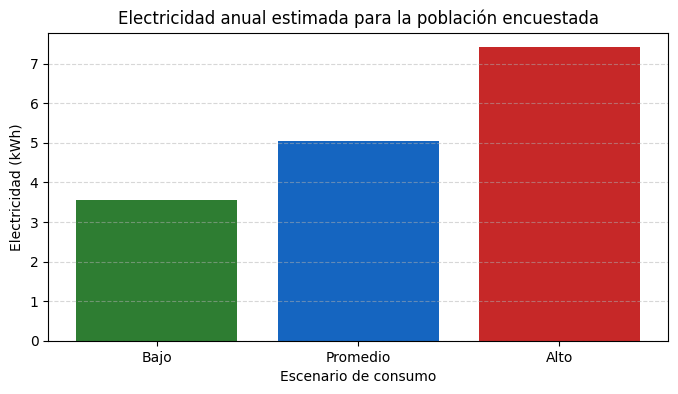

In [14]:
# GRÁFICA DE ELECTRICIDAD ANUAL POR ESCENARIO
plt.figure(figsize=(8, 4))

plt.bar(
    total_plantel["Escenario"],
    total_plantel["Electricidad anual (kWh)"],
    color=["#2E7D32", "#1565C0", "#C62828"]
)

plt.title("Electricidad anual estimada para la población encuestada")
plt.xlabel("Escenario de consumo")
plt.ylabel("Electricidad (kWh)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [15]:
# CONEXIÓN CON LA RED NEURONAL
# Se utilizan las mismas seis variables con las que se entrenó la red
X_red = clean_df[
    [
        "Frecuencia_Uso",
        "Cantidad_Prompts",
        "Reintentos",
        "Trabajo_Sin_Cambio",
        "Capacitacion_Previa",
        "Necesidad_Complejidad"
    ]
].values

# Se aplica la misma normalización utilizada durante el entrenamiento
X_red_escalado = scaler.transform(X_red)

# La red predice probabilidades para los perfiles 0, 1 y 2
probabilidades = model.predict(X_red_escalado, verbose=0)

# Se selecciona el perfil con mayor probabilidad
perfiles_predichos = np.argmax(probabilidades, axis=1)

# Se agrega el perfil predicho a la base de EcoPrompt
eco_resultados = clean_df.copy()
eco_resultados["Perfil_Predicho"] = perfiles_predichos

eco_resultados.head()

,Frecuencia_Uso,Cantidad_Prompts,Reintentos,Trabajo_Sin_Cambio,Capacitacion_Previa,Necesidad_Complejidad,Perfil_Observado,Perfil_Predicho
0,2,4,4,2,0,1,2,2
1,3,3,2,2,0,5,2,2
2,1,2,3,2,1,3,2,2
3,1,1,2,1,1,4,1,1
4,2,2,1,1,0,1,1,0


In [16]:
# RECOMENDACIONES SEGÚN EL PERFIL PREDICHO
def recomendacion(perfil):
    if perfil == 0:
        return "Uso bajo. Se recomienda mantener una revisión de la información antes de utilizarla."
    elif perfil == 1:
        return "Uso intermedio. Se recomienda formular prompts más claros y verificar las fuentes antes de entregar trabajos."
    else:
        return "Uso avanzado. Se recomienda reducir reintentos, revisar la información y evitar entregar respuestas sin cambios significativos."


eco_resultados["Recomendacion"] = eco_resultados["Perfil_Predicho"].apply(recomendacion)

eco_resultados[
    [
        "Frecuencia_Uso",
        "Cantidad_Prompts",
        "Reintentos",
        "Perfil_Predicho",
        "Recomendacion"
    ]
].head()

,Frecuencia_Uso,Cantidad_Prompts,Reintentos,Perfil_Predicho,Recomendacion
0,2,4,4,2,Uso avanzado. Se recomienda reducir reintentos...
1,3,3,2,2,Uso avanzado. Se recomienda reducir reintentos...
2,1,2,3,2,Uso avanzado. Se recomienda reducir reintentos...
3,1,1,2,1,Uso intermedio. Se recomienda formular prompts...
4,2,2,1,0,Uso bajo. Se recomienda mantener una revisión ...


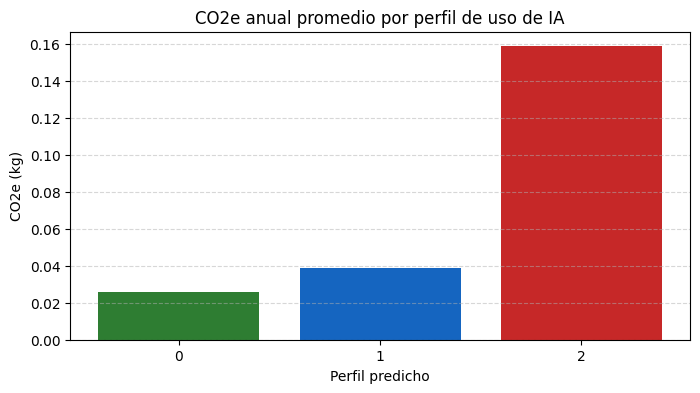

In [18]:
# RELACIÓN ENTRE PERFIL Y HUELLA ESTIMADA
# Se une la huella anual con el perfil predicho
huella_perfil = huella_promedio.copy()
huella_perfil["Perfil_Predicho"] = eco_resultados["Perfil_Predicho"].values

# Promedio de huella por perfil
resumen_perfil = huella_perfil.groupby("Perfil_Predicho")[
    [
        "Electricidad_año_kwh",
        "CO2_año_kg",
        "Agua_año_litros",
        "Costo_año_MXN"
    ]
].mean()

resumen_perfil

# GRÁFICA DE CO2e ANUAL POR PERFIL

plt.figure(figsize=(8, 4))

plt.bar(
    resumen_perfil.index.astype(str),
    resumen_perfil["CO2_año_kg"],
    color=["#2E7D32", "#1565C0", "#C62828"]
)

plt.title("CO2e anual promedio por perfil de uso de IA")
plt.xlabel("Perfil predicho")
plt.ylabel("CO2e (kg)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [19]:
# RESUMEN FINAL DE ECOPROMPT MX

print("RESUMEN FINAL DE ECOPROMPT MX")
print("=" * 50)

print(f"Estudiantes analizados: {len(clean_df)}")
print()

print("Escenario bajo:")
print(f"Electricidad anual: {total_bajo['Electricidad_año_kwh']:.4f} kWh")
print(f"CO2e anual: {total_bajo['CO2_año_kg']:.4f} kg")
print(f"Agua anual: {total_bajo['Agua_año_litros']:.4f} litros")
print(f"Costo anual: ${total_bajo['Costo_año_MXN']:.4f} MXN")
print()

print("Escenario promedio:")
print(f"Electricidad anual: {total_promedio['Electricidad_año_kwh']:.4f} kWh")
print(f"CO2e anual: {total_promedio['CO2_año_kg']:.4f} kg")
print(f"Agua anual: {total_promedio['Agua_año_litros']:.4f} litros")
print(f"Costo anual: ${total_promedio['Costo_año_MXN']:.4f} MXN")
print()

print("Escenario alto:")
print(f"Electricidad anual: {total_alto['Electricidad_año_kwh']:.4f} kWh")
print(f"CO2e anual: {total_alto['CO2_año_kg']:.4f} kg")
print(f"Agua anual: {total_alto['Agua_año_litros']:.4f} litros")
print(f"Costo anual: ${total_alto['Costo_año_MXN']:.4f} MXN")

RESUMEN FINAL DE ECOPROMPT MX
Estudiantes analizados: 31

Escenario bajo:
Electricidad anual: 3.5568 kWh
CO2e anual: 1.5579 kg
Agua anual: 3.8532 litros
Costo anual: $13.5158 MXN

Escenario promedio:
Electricidad anual: 5.0388 kWh
CO2e anual: 2.2070 kg
Agua anual: 4.7424 litros
Costo anual: $19.1474 MXN

Escenario alto:
Electricidad anual: 7.4100 kWh
CO2e anual: 3.2456 kg
Agua anual: 13.3380 litros
Costo anual: $28.1580 MXN


#Resultados anuales de EcoPrompt MX (31 estudiantes)

| Escenario | Electricidad (kWh) | CO₂e (kg) | Agua (L) | Costo (MXN) |
|---|---|---|---|---|
| Bajo | 3.56 | 1.56 | 3.85 | $13.52 |
| Promedio | 5.04 | 2.21 | 4.74 | $19.15 |
| Alto | 7.41 | 3.25 | 13.34 | $28.16 |

#Promedio por estudiante al año

| Escenario | Electricidad (kWh) | CO₂e (kg) | Agua (L) | Costo (MXN) |
|---|---|---|---|---|
| Bajo | 0.11 | 0.05 | 0.12 | $0.44 |
| Promedio  | 0.16 | 0.07 | 0.15 | $0.62 |
| Alto | 0.24 | 0.10 | 0.43 | $0.91 |

#Metodología

- *Consumo por consulta de texto estándar:* electricidad (Wh) y agua (mL) según tres escenarios: bajo (0.24 Wh y 0.26 mL), promedio (0.34 Wh y 0.32 mL) y alto (0.5 Wh y 0.90 mL).
- *CO₂e:* se calculó multiplicando la electricidad por el factor de emisión del Sistema Eléctrico Nacional (0.438 kg CO₂e/kWh).
- *Costo:* tarifa eléctrica comercial de $3.80 MXN por kWh.
- *Agua:* se tomó directamente de los mL por consulta de cada escenario, no se calculó a partir de los kWh.

#Limitaciones

- Los valores por consulta provienen de fuentes distintas (mediciones o declaraciones de proveedores y estimaciones externas) y no son totalmente comparables entre sí.
- Los resultados cambian según el modelo, la longitud del prompt, la región y la infraestructura del proveedor.
- Los cálculos excluyen el entrenamiento de los modelos y la fabricación del hardware.
- El costo es una estimacion del valor de la electricidad consumida, calculado con la tarifa comercial de $3.80 MXN/kwh.No representa un gasto real para el estudiante ni incluye suscripciones, equipos o internet.